# German Traffic Sign Recognition

The main objective of this project is to develop a Convolutional Neural Network (CNN) model capable of classifying traffic signs with high accuracy using the German Traffic Sign Recognition Benchmark (GTSRB) dataset.

<img src='https://images.contentstack.io/v3/assets/blt1bd0ccbd0b7d1870/blt49d018c20ba60c47/68a302add002822951c8357d/autobahn_GettyImages-77946575_(2).jpg' width='750'>

In [1]:
import cv2
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Conv2D,Dense, Flatten, Input, MaxPooling2D, Dropout, BatchNormalization, Reshape
import os

import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.applications import VGG16, VGG19, ResNet50
import warnings
warnings.filterwarnings('ignore')

In [2]:
train_df=pd.read_csv("Train.csv")
test_df=pd.read_csv("Test.csv")
meta_df=pd.read_csv("Meta.csv")

In [3]:
train_dir="Train"
test_dir="Test"
meta_dir="Meta"

In [4]:
label_cod={0:'Speed limit (20km/h)',1:'Speed limit (30km/h)', 2:'Speed limit (50km/h)', 
           3:'Speed limit (60km/h)', 4:'Speed limit (70km/h)', 5:'Speed limit (80km/h)', 
           6:'End of speed limit (80km/h)', 7:'Speed limit (100km/h)', 8:'Speed limit (120km/h)', 
           9:'No passing', 10:'No passing veh over 3.5 tons', 11:'Right-of-way at intersection', 
           12:'Priority road', 13:'Yield', 14:'Stop', 15:'No vehicles', 16:'Veh > 3.5 tons prohibited', 
           17:'No entry', 18:'General caution', 19:'Dangerous curve left', 20:'Dangerous curve right', 
           21:'Double curve', 22:'Bumpy road', 23:'Slippery road', 24:'Road narrows on the right', 
           25:'Road work', 26:'Traffic signals', 27:'Pedestrians', 28:'Children crossing', 
           29:'Bicycles crossing', 30:'Beware of ice/snow',31:'Wild animals crossing', 
           32:'End speed + passing limits', 33:'Turn right ahead', 34:'Turn left ahead', 35:'Ahead only', 
           36:'Go straight or right', 37:'Go straight or left', 38:'Keep right', 39:'Keep left', 
           40:'Roundabout mandatory', 41:'End of no passing', 42:'End no passing veh > 3.5 tons' }

In [5]:
os.listdir(train_dir)

['0',
 '1',
 '10',
 '11',
 '12',
 '13',
 '14',
 '15',
 '16',
 '17',
 '18',
 '19',
 '2',
 '20',
 '21',
 '22',
 '23',
 '24',
 '25',
 '26',
 '27',
 '28',
 '29',
 '3',
 '30',
 '31',
 '32',
 '33',
 '34',
 '35',
 '36',
 '37',
 '38',
 '39',
 '4',
 '40',
 '41',
 '42',
 '5',
 '6',
 '7',
 '8',
 '9']

In [6]:
labels=['0','1','10','11','12','13','14','15', '16','17','18','19','2','20','21','22','23','24','25','26','27','28','29','3','30','31','32','33','34','35','36','37','38','39','4','40','41','42','5','6','7','8', '9']

In [7]:
img_list1 = []
label_list1 = []

for label in labels:
    for img_file in os.listdir(train_dir + "/" + label):
        img_list1.append(train_dir + "/" + label + "/" + img_file)
        label_list1.append(int(label))

In [8]:
train_df=pd.DataFrame({'img':img_list1,'label':label_list1})

In [9]:
train_df['encode_label']=train_df['label'].map(label_cod)

In [10]:
train_df.sample(9)

,img,label,encode_label
6296,Train/12/00012_00017_00026.png,12,Priority road
22159,Train/3/00003_00017_00019.png,3,Speed limit (60km/h)
20629,Train/27/00027_00001_00019.png,27,Pedestrians
29925,Train/4/00004_00004_00016.png,4,Speed limit (70km/h)
8732,Train/13/00013_00029_00002.png,13,Yield
19256,Train/25/00025_00025_00026.png,25,Road work
22978,Train/3/00003_00044_00028.png,3,Speed limit (60km/h)
30557,Train/4/00004_00025_00018.png,4,Speed limit (70km/h)
35946,Train/7/00007_00035_00007.png,7,Speed limit (100km/h)


In [11]:
os.listdir(test_dir)

['00000.png',
 '00001.png',
 '00002.png',
 '00003.png',
 '00004.png',
 '00005.png',
 '00006.png',
 '00007.png',
 '00008.png',
 '00009.png',
 '00010.png',
 '00011.png',
 '00012.png',
 '00013.png',
 '00014.png',
 '00015.png',
 '00016.png',
 '00017.png',
 '00018.png',
 '00019.png',
 '00020.png',
 '00021.png',
 '00022.png',
 '00023.png',
 '00024.png',
 '00025.png',
 '00026.png',
 '00027.png',
 '00028.png',
 '00029.png',
 '00030.png',
 '00031.png',
 '00032.png',
 '00033.png',
 '00034.png',
 '00035.png',
 '00036.png',
 '00037.png',
 '00038.png',
 '00039.png',
 '00040.png',
 '00041.png',
 '00042.png',
 '00043.png',
 '00044.png',
 '00045.png',
 '00046.png',
 '00047.png',
 '00048.png',
 '00049.png',
 '00050.png',
 '00051.png',
 '00052.png',
 '00053.png',
 '00054.png',
 '00055.png',
 '00056.png',
 '00057.png',
 '00058.png',
 '00059.png',
 '00060.png',
 '00061.png',
 '00062.png',
 '00063.png',
 '00064.png',
 '00065.png',
 '00066.png',
 '00067.png',
 '00068.png',
 '00069.png',
 '00070.png',
 '0007

In [12]:
ttest_df = pd.read_csv("Test.csv")

test_img_list = [path for path in ttest_df['Path']]

test_df = pd.DataFrame({
    'img': test_img_list,
    'label': ttest_df['ClassId']
})

test_df['encode_label'] = test_df['label'].map(label_cod)

In [13]:
test_df.sample(5)

,img,label,encode_label
11866,Test/11866.png,21,Double curve
6784,Test/06784.png,12,Priority road
9182,Test/09182.png,24,Road narrows on the right
7935,Test/07935.png,40,Roundabout mandatory
9522,Test/09522.png,1,Speed limit (30km/h)


In [14]:
os.listdir(meta_dir)

['.~lock.ClassesInformation.ods#',
 '.~lock.ClassesInformationStrong.ods#',
 '0.png',
 '1.png',
 '10.png',
 '11.png',
 '12.png',
 '13.png',
 '14.png',
 '15.png',
 '16.png',
 '17.png',
 '18.png',
 '19.png',
 '2.png',
 '20.png',
 '21.png',
 '22.png',
 '23.png',
 '24.png',
 '25.png',
 '26.png',
 '27.png',
 '28.png',
 '29.png',
 '3.png',
 '30.png',
 '31.png',
 '32.png',
 '33.png',
 '34.png',
 '35.png',
 '36.png',
 '37.png',
 '38.png',
 '39.png',
 '4.png',
 '40.png',
 '41.png',
 '42.png',
 '5.png',
 '6.png',
 '7.png',
 '8.png',
 '9.png']

In [15]:
meta_files=[f for f in os.listdir(meta_dir) if f.endswith('.png')]
meta_df=pd.DataFrame({'img': [os.path.join(meta_dir, f) for f in meta_files],'label': [int(f.split('.')[0]) for f in meta_files]})
meta_df['encode_label'] = meta_df['label'].map(label_cod)

In [16]:
meta_df.sample(5)

,img,label,encode_label
25,Meta\31.png,31,Wild animals crossing
35,Meta\40.png,40,Roundabout mandatory
22,Meta\29.png,29,Bicycles crossing
15,Meta\22.png,22,Bumpy road
31,Meta\37.png,37,Go straight or left


In [17]:
import seaborn as sns

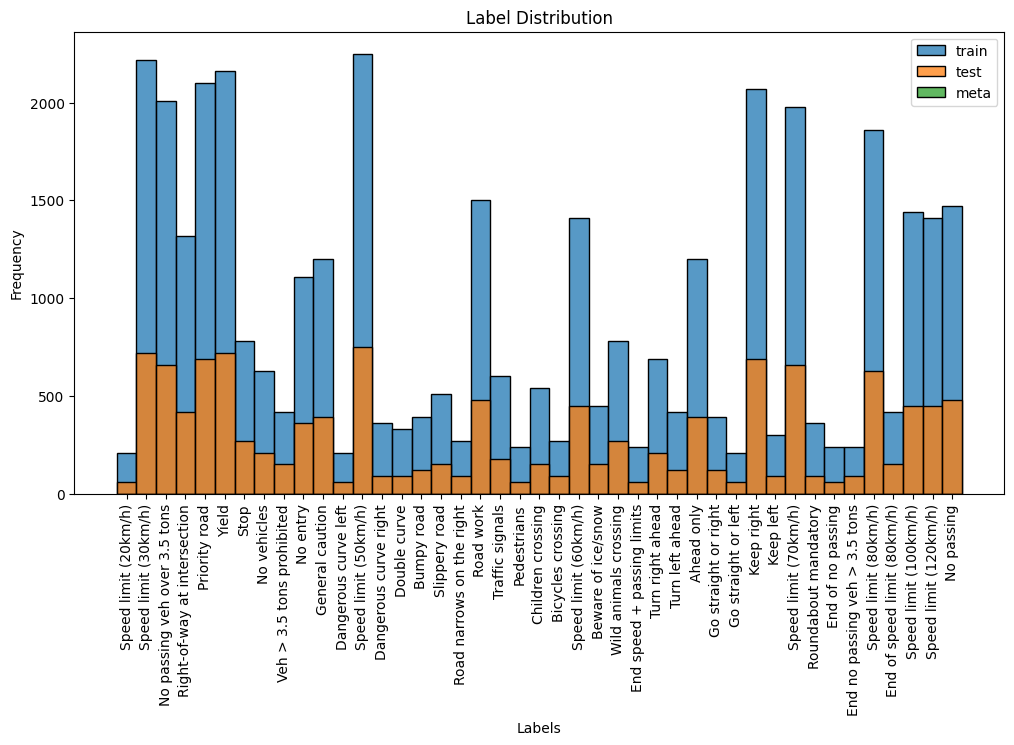

In [18]:
plt.figure(figsize=(12, 6))
sns.histplot(x=train_df['encode_label'], label='train')
sns.histplot(x=test_df['encode_label'], label='test')
sns.histplot(x=meta_df['encode_label'], label='meta')
plt.xticks(rotation=90) 
plt.xlabel('Labels')
plt.ylabel('Frequency')
plt.title('Label Distribution')
plt.legend();

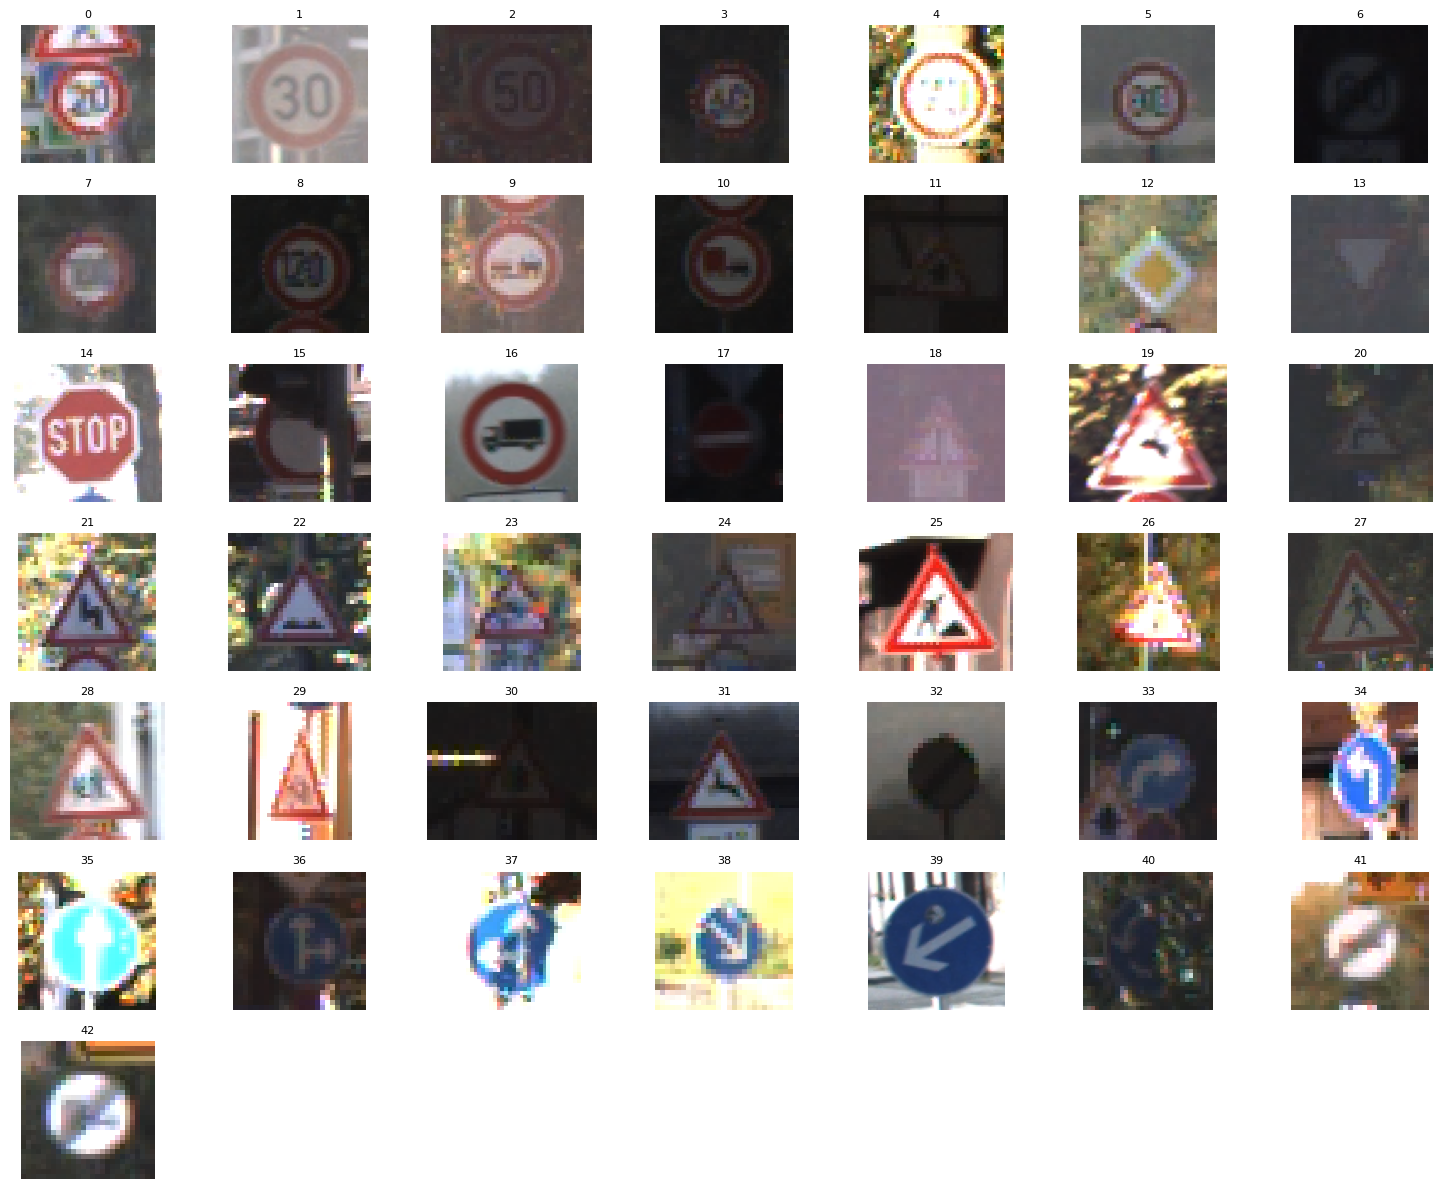

In [19]:
sample_df=train_df.drop_duplicates('label').sort_values('label')

plt.figure(figsize=(15, 12))
for i, row in enumerate(sample_df.values):
    plt.subplot(7, 7, i+1) # 43 sınıf için 7x7 grid yeterli
    plt.imshow(plt.imread(row[0])) # row[0] resim yolu (img)
    plt.title(row[1], fontsize=8) # row[1] etiket (label)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [20]:
df=pd.concat([train_df, test_df, meta_df], ignore_index=True)

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51882 entries, 0 to 51881
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   img           51882 non-null  object
 1   label         51882 non-null  int64 
 2   encode_label  51882 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.2+ MB


In [22]:
df.sample(10)

,img,label,encode_label
24264,Train/31/00031_00025_00024.png,31,Wild animals crossing
530,Train/1/00001_00010_00020.png,1,Speed limit (30km/h)
51372,Test/12163.png,25,Road work
15367,Train/2/00002_00033_00007.png,2,Speed limit (50km/h)
50806,Test/11597.png,1,Speed limit (30km/h)
31856,Train/40/00040_00002_00027.png,40,Roundabout mandatory
32711,Train/5/00005_00003_00012.png,5,Speed limit (80km/h)
24434,Train/32/00032_00005_00014.png,32,End speed + passing limits
50313,Test/11104.png,4,Speed limit (70km/h)
30543,Train/4/00004_00025_00004.png,4,Speed limit (70km/h)


In [23]:
#Normalization

In [24]:
x = []
for img_path in df['img']: 
    img=cv2.imread(str(img_path))
    if img is None:
        print(f"Resim yüklenemedi: {img_path}") 
        continue
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img=cv2.resize(img, (30, 30))
    img=img / 255.0
    x.append(img)

In [25]:
x=np.array(x)

In [26]:
x.shape

(51882, 30, 30, 3)

In [27]:
y=df[['label']]

In [28]:
#CNN Modelling

In [29]:
x_train,x_test,y_train,y_test=train_test_split(x,y, random_state=42, test_size=0.20)

In [30]:
y_train = np.array(y_train)
y_test = np.array(y_test)

In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

model = Sequential([
    Input(shape=(30, 30, 3)),
    
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.2),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.3),

    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.4),

    Flatten(),
    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(43, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [32]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop=EarlyStopping(monitor='val_loss',patience=10)

In [33]:
history=model.fit(x_train,y_train, validation_data=(x_test,y_test), epochs=20, callbacks=[early_stop], verbose=1)

Epoch 1/20
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 114s 83ms/step - accuracy: 0.6915 - loss: 1.1308 - val_accuracy: 0.9668 - val_loss: 0.1070
Epoch 2/20
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 102s 79ms/step - accuracy: 0.9503 - loss: 0.1582 - val_accuracy: 0.9874 - val_loss: 0.0452
Epoch 3/20
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 101s 78ms/step - accuracy: 0.9692 - loss: 0.0973 - val_accuracy: 0.9896 - val_loss: 0.0322
Epoch 4/20
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 97s 75ms/step - accuracy: 0.9752 - loss: 0.0814 - val_accuracy: 0.9928 - val_loss: 0.0263
Epoch 5/20
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 101s 78ms/step - accuracy: 0.9776 - loss: 0.0700 - val_accuracy: 0.9941 - val_loss: 0.0191
Epoch 6/20
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 94s 72ms/step - accuracy: 0.9824 - loss: 0.0559 - val_accuracy: 0.9952 - val_loss: 0.0158
Epoch 7/20
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 87s 67ms/step - accuracy: 0.9843 - loss: 0.0488 - val_accuracy: 0.9922 - val_loss: 0.0239
Epoch 8/20
1298/1298 ━━━━━━━━━━━━━━━━━━━━ 86s 67ms/step - accuracy: 0.98

In [34]:
model.save('german_traffic_sign.h5')

In [35]:
import pickle
import tensorflow as tf


with open('german_traffic_model.pkl', 'wb') as f:
    pickle.dump(model, f)

with open('labels.pkl', 'wb') as f:
    pickle.dump(label_cod, f)
    
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open('traffic_sign_model.tflite', 'wb') as f:
    f.write(tflite_model)

print("İşlem Tamam: 'traffic_model.pkl', 'labels.pkl' ve 'traffic_sign_model.tflite' dosyaları oluşturuldu.")

INFO:tensorflow:Assets written to: C:\Users\furka\AppData\Local\Temp\tmp1x0oayys\assets


INFO:tensorflow:Assets written to: C:\Users\furka\AppData\Local\Temp\tmp1x0oayys\assets


Saved artifact at 'C:\Users\furka\AppData\Local\Temp\tmp1x0oayys'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 30, 30, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 43), dtype=tf.float32, name=None)
Captures:
  2417292894352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2417292893968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2417293107344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2417292680976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2417292894160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2417293107728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2417293107536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2417292680784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2417294651856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2417294651664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  241729

In this project, a Deep Learning model based on Convolutional Neural Networks (CNN) was successfully developed and evaluated using the German Traffic Sign Recognition Benchmark (GTSRB) dataset. The model effectively classifies various traffic signs, demonstrating high performance and strong capability in image recognition for autonomous driving applications.